# 01 — Análise Exploratória de Dados (EDA) e Divisão Estratificada

**Atividade Final de Redes Neurais Artificiais — EAD Unifor (TrashNet)**

Este notebook inspeciona o dataset oficial `dataset-resized.zip` (2.527 imagens originais em `512 × 384`), verifica integridade, dimensões, canais de cor e duplicações via MD5, remove os 6 arquivos pertencentes aos 3 pares conflitantes (restando 2.521 imagens limpas), realiza a divisão estratificada fixa (70% treino, 15% validação, 15% teste com `seed = 42`) e exibe a distribuição e exemplos das 6 classes.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

BASE_DIR = Path('..').resolve()
with open(BASE_DIR / 'results' / 'eda_summary.json', 'r', encoding='utf-8') as f:
    eda = json.load(f)

print('Total original:', eda['total_images_original'])
print('Arquivos removidos por duplicidade MD5 conflitante:', eda['removed_conflicting_duplicates'])
print('Total limpo utilizado:', eda['total_images'])
print('Arquivos corrompidos:', eda['corrupted_files'])
print('Dimensões:', eda['dimensions_summary'])
print('Modos de cor:', eda['color_modes'])
print('Pares MD5 conflitantes detectados:', eda['duplicate_md5_pairs_original'])
print('Totais por divisão (seed=42):', eda['split_totals'])
print('Média RGB no treino [0,1]:', eda['train_rgb_mean_0_1'])
print('Desvio padrão RGB no treino [0,1]:', eda['train_rgb_std_0_1'])

Total original: 2527
Arquivos removidos por duplicidade MD5 conflitante: ['glass/glass115.jpg', 'glass/glass176.jpg', 'glass/glass389.jpg', 'metal/metal91.jpg', 'plastic/plastic152.jpg', 'plastic/plastic332.jpg']
Total limpo utilizado: 2521
Arquivos corrompidos: 0
Dimensões: [{'width': 512, 'height': 384, 'count': 2521}]
Modos de cor: {'RGB': 2521}
Pares MD5 conflitantes detectados: [['plastic/plastic152.jpg', 'glass/glass176.jpg'], ['plastic/plastic332.jpg', 'glass/glass389.jpg'], ['metal/metal91.jpg', 'glass/glass115.jpg']]
Totais por divisão (seed=42): {'train': 1764, 'val': 378, 'test': 379}
Média RGB no treino [0,1]: [0.6727, 0.6397, 0.6047]
Desvio padrão RGB no treino [0,1]: [0.1837, 0.1828, 0.1934]


In [2]:
df_dist = pd.DataFrame(eda['class_distribution']).T
display(df_dist)

,total,train,val,test,pct_total,class_weight
glass,498.0,348.0,75.0,75.0,19.75,0.8448
paper,594.0,416.0,89.0,89.0,23.56,0.7067
cardboard,403.0,282.0,60.0,61.0,15.99,1.0426
plastic,480.0,336.0,72.0,72.0,19.04,0.8750
metal,409.0,286.0,61.0,62.0,16.22,1.0280
trash,137.0,96.0,21.0,20.0,5.43,3.0625


## Distribuição Estratificada e Exemplos Visuais

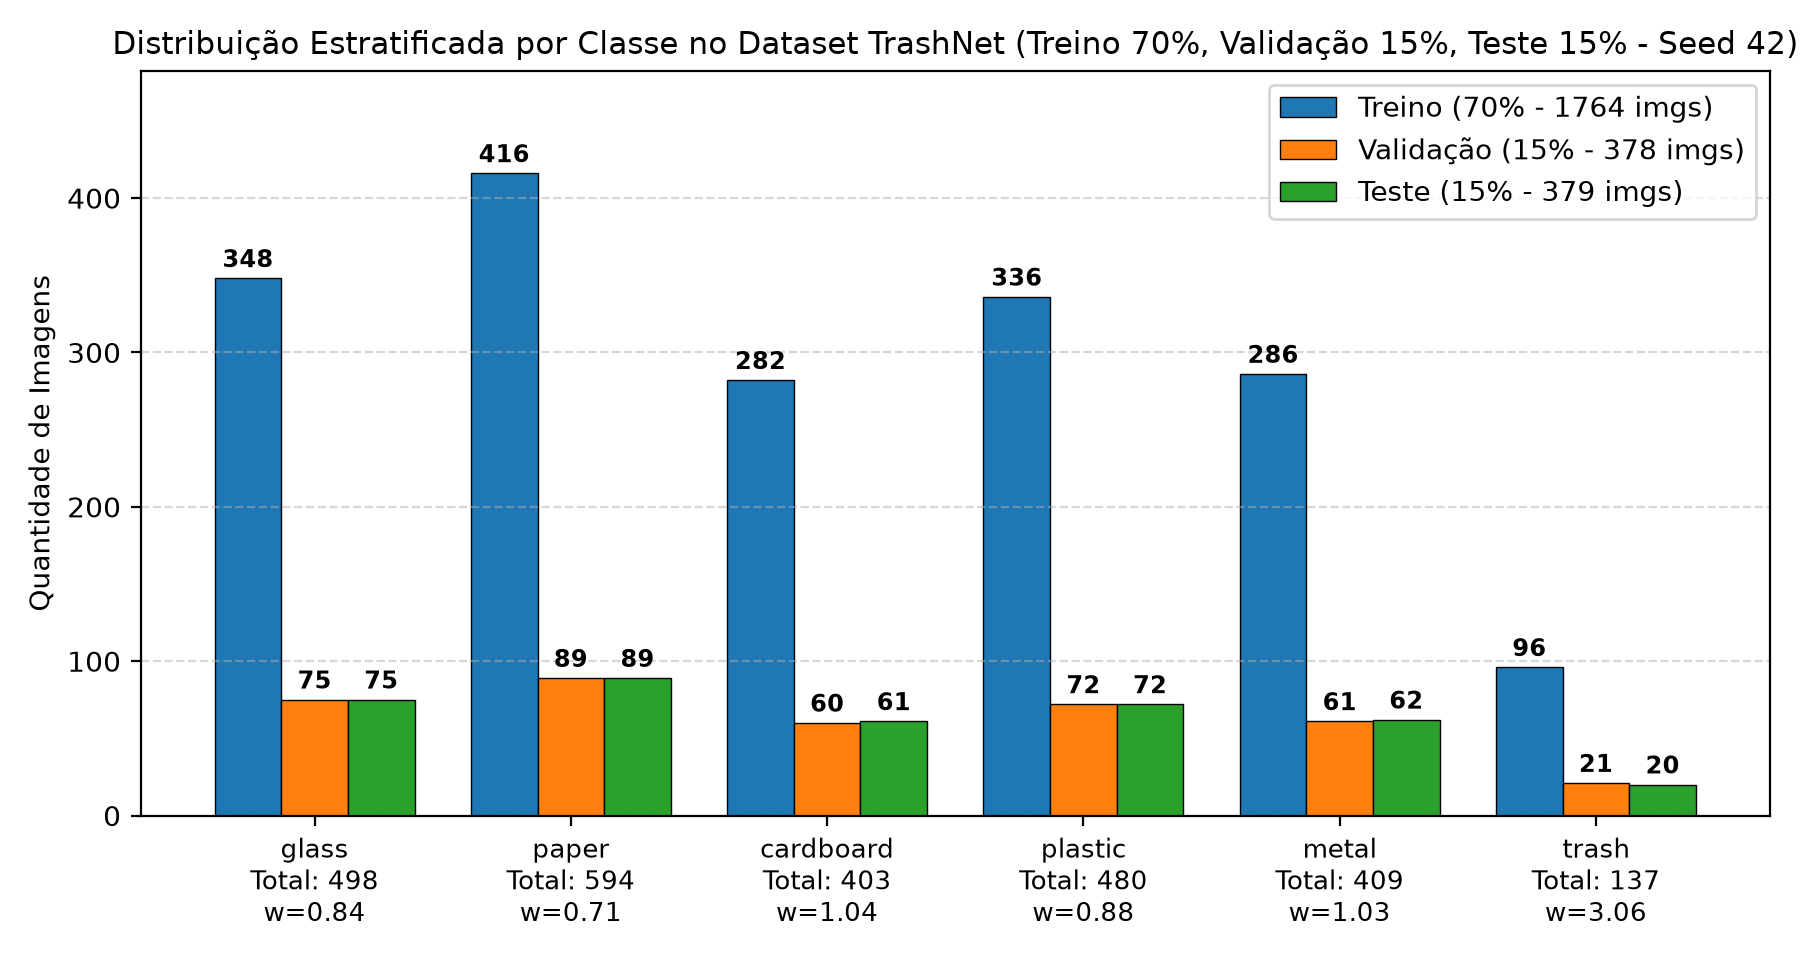

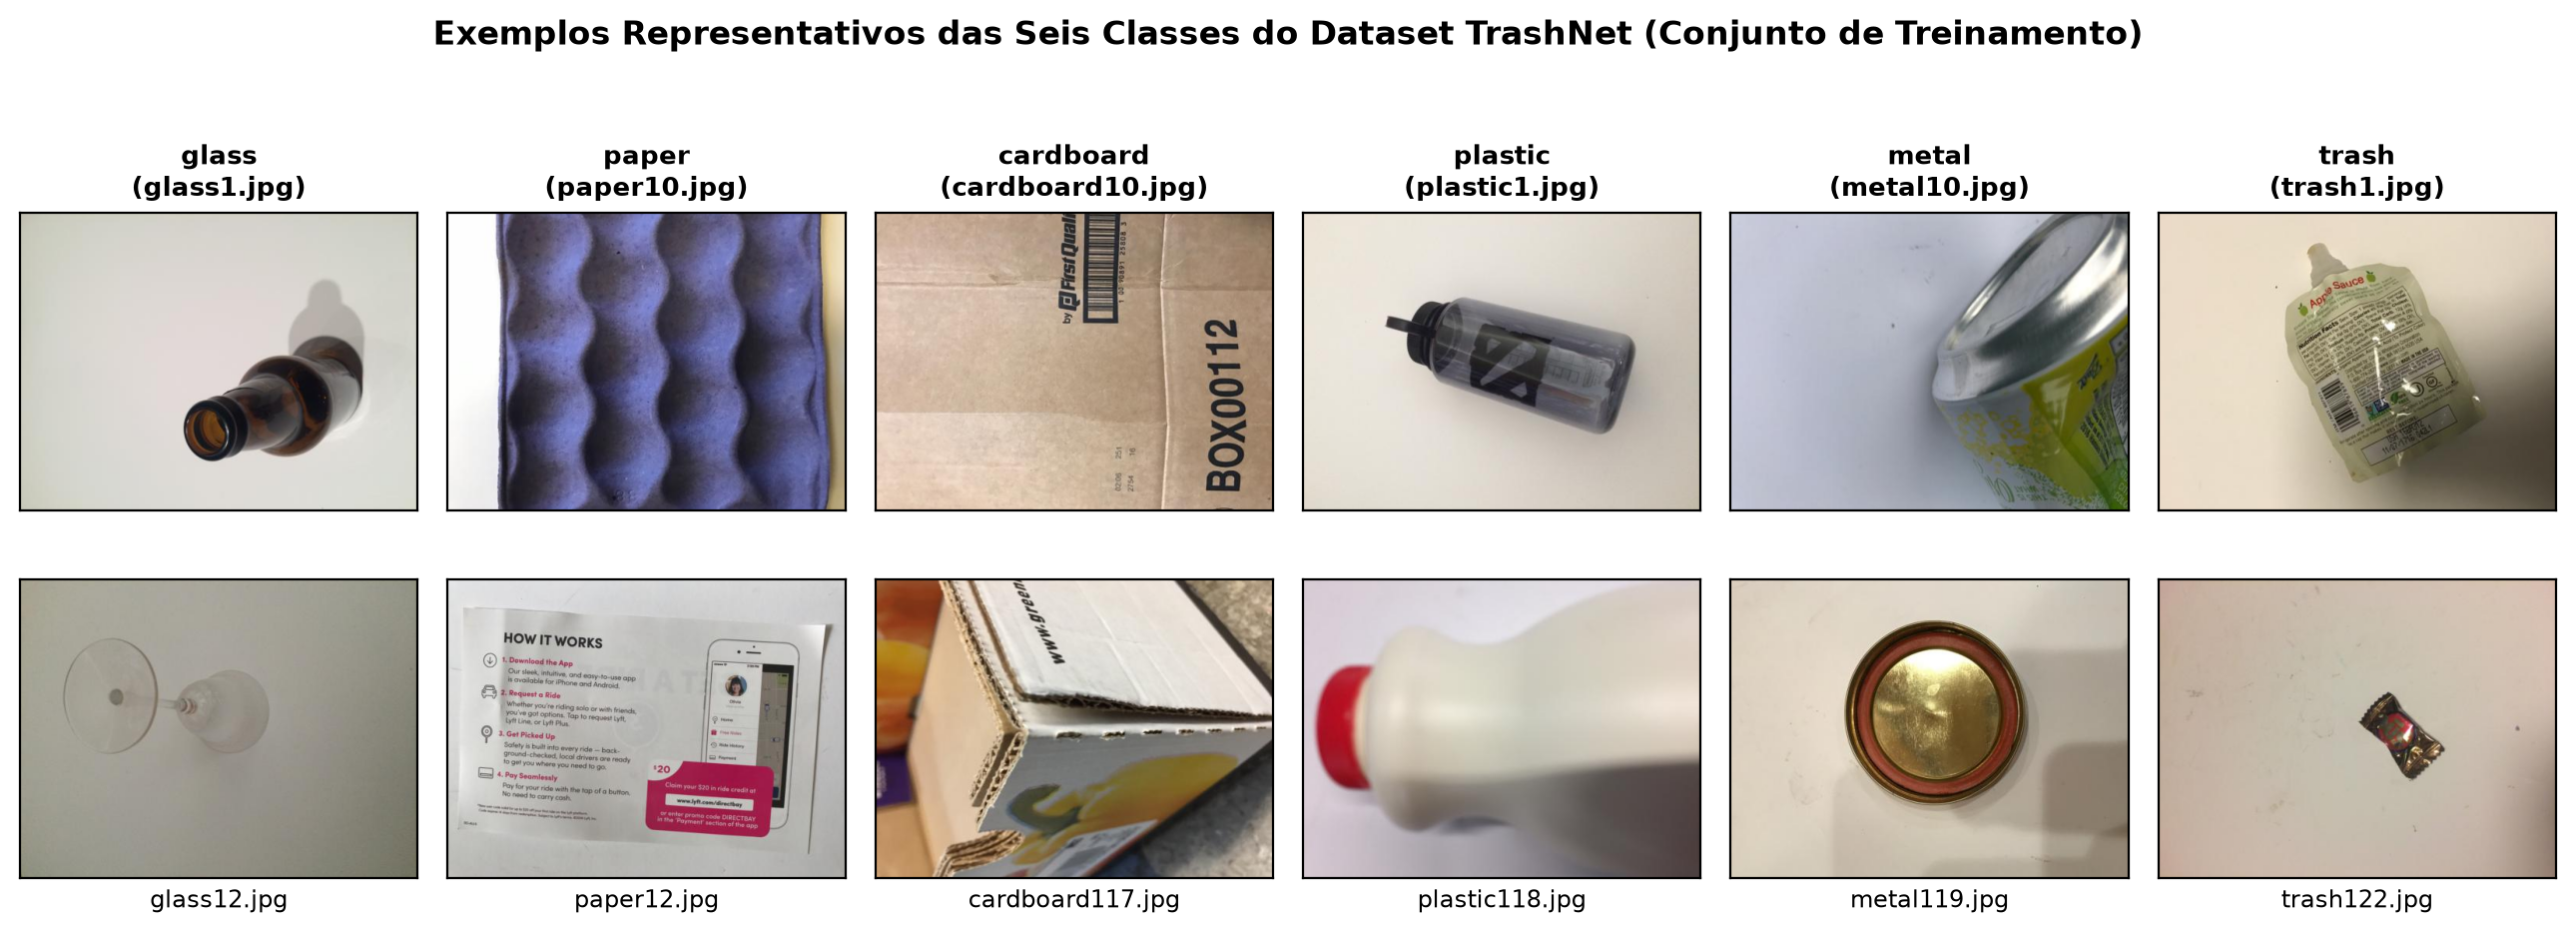

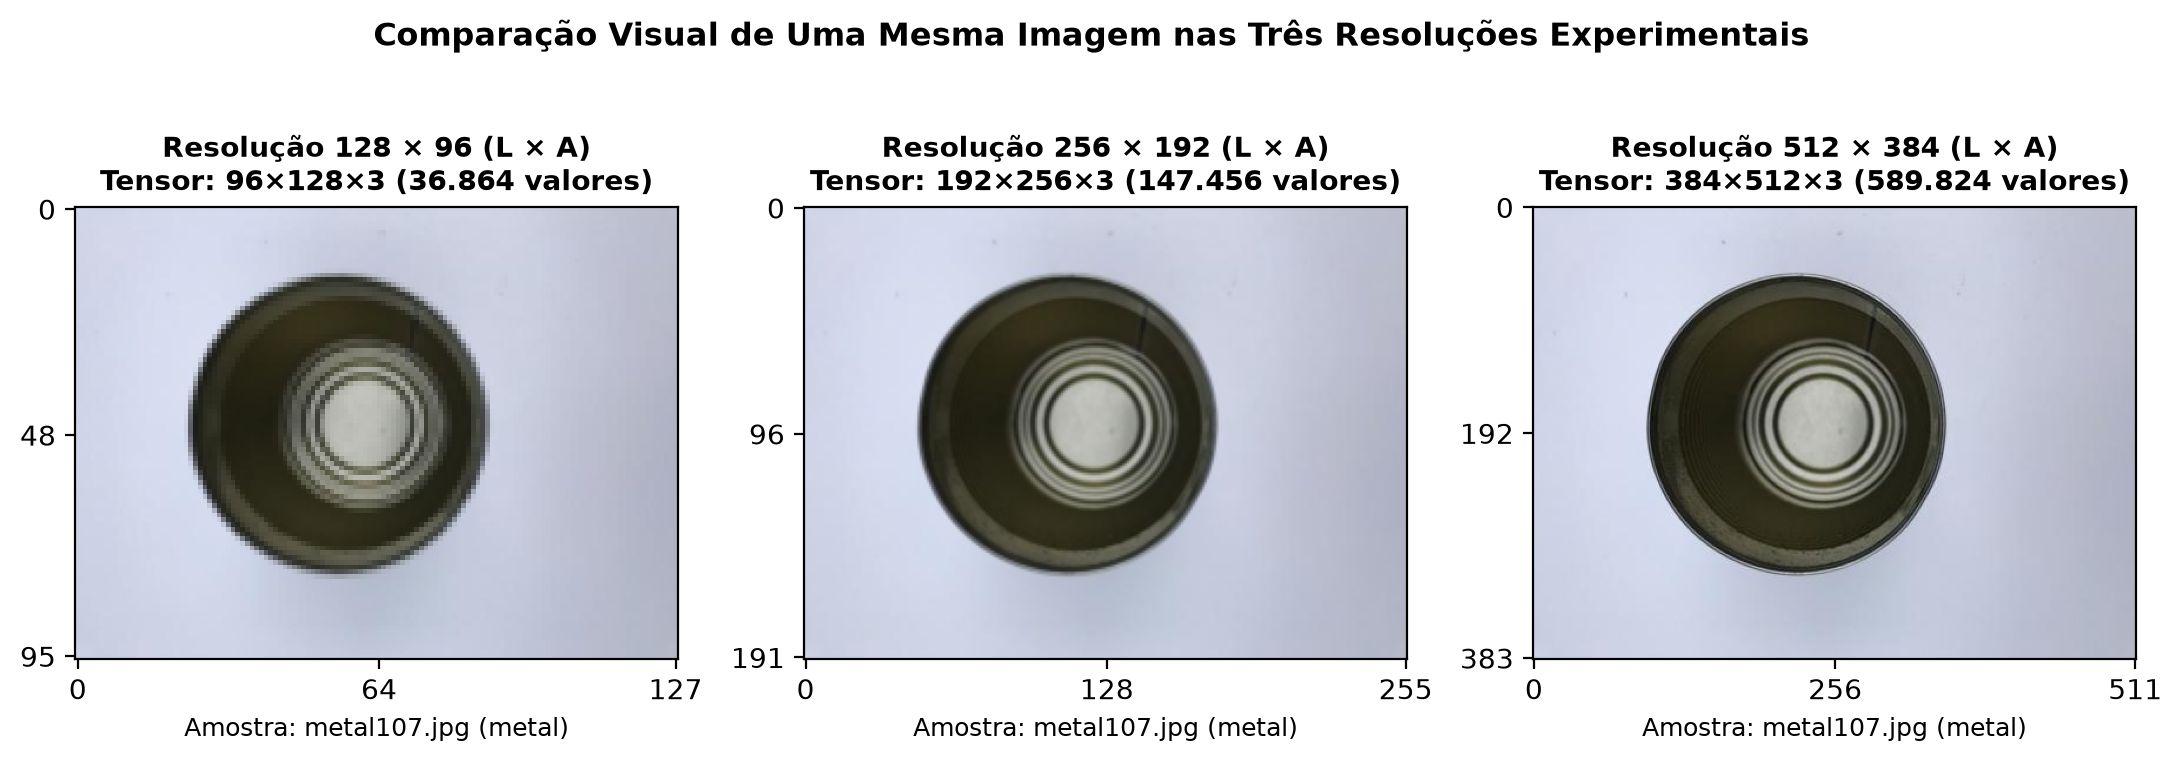

In [3]:
for fig_name in ['fig1_distribuicao_classes.png', 'fig2_exemplos_classes.png', 'fig3_comparacao_resolucoes.png']:
    display(Image(filename=str(BASE_DIR / 'results' / 'figures' / fig_name)))